In [ ]:
pip install shap


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import shap

df = pd.read_csv("C:/Users/angel/Downloads/diabetes (1).csv")
print(df.head())
df.shape
df.columns
# 768, 9

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

-WEIGHT CAN BE CALULATED BY TAKING THE INVERSE OF THE CONNECTIONS AT EACH LAYER
-

In [ ]:
# x will be the 8 features
# y will be the outcome

from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay)


X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42, test_size=0.3)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

original_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred)
}
original_metrics

{'Accuracy': 0.7402597402597403,
 'Precision': 0.6666666666666666,
 'Recall': 0.5185185185185185}

In [ ]:
# from sklearn.tree import DecisionTree

explainer = shap.Explainer(clf, X_train, max_samples = 537)
shap_values = explainer(X_test)

Background dataset has 537 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=537 when initializing the masker.


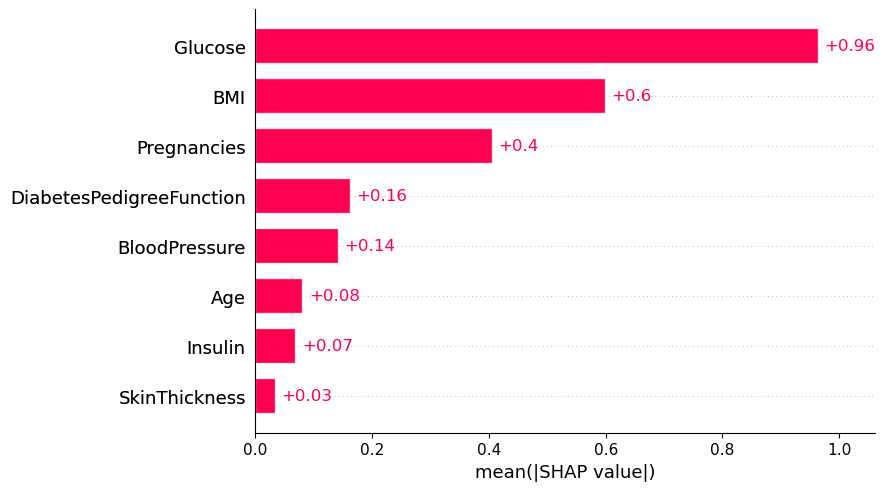

In [ ]:
shap.plots.bar(shap_values)

In [ ]:
# absolute values of shap: represented by the bars
# increases predictabikity of negative class: lower values
# bar is plotting the absolute values

In [ ]:
df['Glucose'].value_counts()

Glucose
99     17
100    17
111    14
125    14
129    14
       ..
56      1
169     1
149     1
65      1
190     1
Name: count, Length: 136, dtype: int64

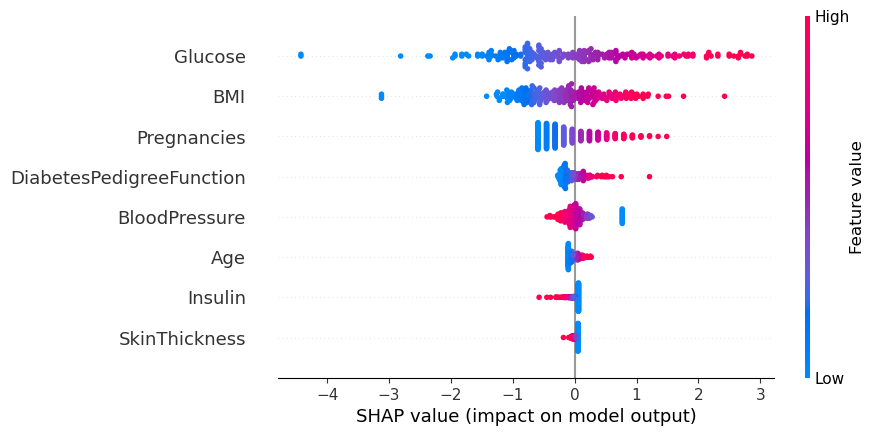

In [ ]:
shap.plots.beeswarm(shap_values)
# individual dots are shap value for a particular feature
# all 231 points are plotted here
# the color code means feature value, glucose is high then shap value is high
# when glucose value is low shap value also reduces
# color coded by feature value, more shap value more impact on the model prediction
# colour represent the features

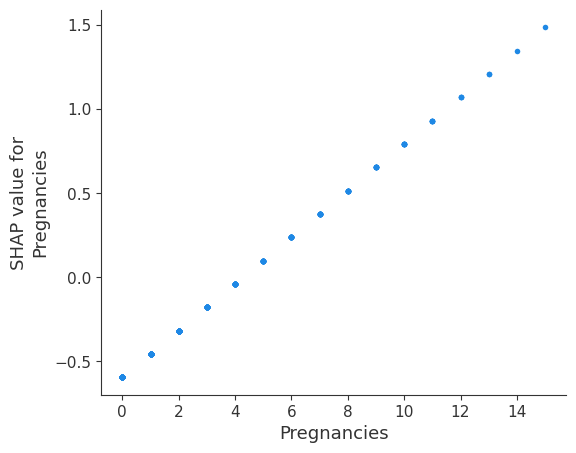

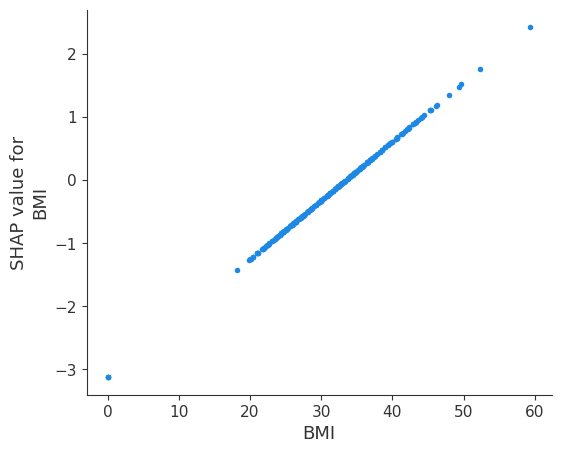

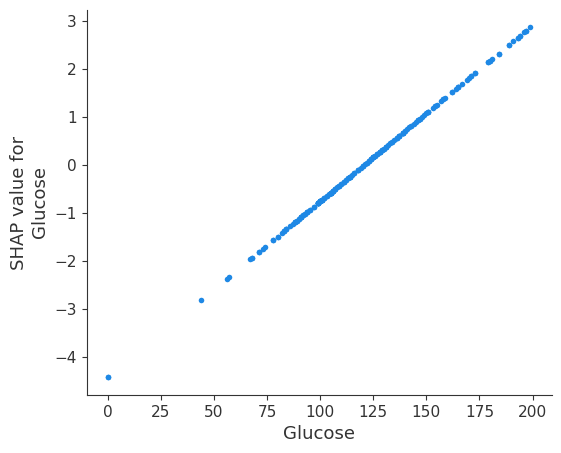

In [ ]:
top_features = np.argsort(np.abs(shap_values.values).mean(axis = 0))[-3:]
top_features_names = [X_test.columns[i] for i in top_features]
for feature in top_features_names:
    shap.dependence_plot(feature, shap_values.values, X_test, interaction_index = None)

# X-axis → The actual values of a chosen feature (e.g., Age, BMI, Income).

# Y-axis → The SHAP values for that feature (how much it pushes the prediction up or down).

explainer is the classifier in shap
logistic regression model is used.

unsupervised learning: The model learns patterns from unlabeled data (only input features, no known outputs).
eg clustering, principal component analysis

Decisions Trees
- Supervised learning has labeled data(input features + output labels)
- Decision tree splits the data into branches based on feature values, forming a tree-like structure.
- can be used for regression and classification
- composition of decision tree:
  1. branches: connections, paths
  2. nodes: root, internal and leaf
- leaf nodes indicate classification: yes or no


- if continuous data is present for a data , you need to determine what threshold is required
- for root we need to determine which feature we are using
- entropy: measures the amount of uncertainty or disorder in a dataset
- high randomness, entropy is high = 1
- randomness = 0, no randomness in the system

- How to determine the features and threshold values?
- for an unbiased coin toss, the entropy is 1
- biased coin toss will have entropy closer to 0 since there is less randomness.

In [ ]:
import numpy as np

def compute_entropy(probs):
    probs = np.array(probs)
    probs = probs / probs.sum()
    entropy = -np.sum(probs * np.log2(probs))
    return entropy

# y = [0.2, 0.8]
# y = [0.5, 0.5]
y = [0.7, 0.3]
print("Entropy:", compute_entropy(y))


Entropy: 0.8812908992306927


relationship between probability and entropy
entropy is high then node is impure , equal probability for both the class
entropy is 0 then the node is a pure node, classifications belonging to one class

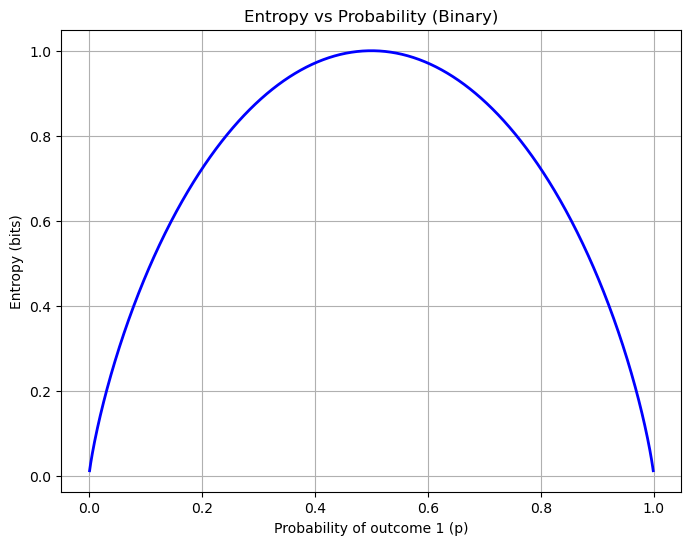

In [ ]:
p = np.linspace(0.001, 0.999, 1000)
entropy = [compute_entropy([pi, 1-pi]) for pi in p]

# Plot
plt.figure(figsize=(8,6))
plt.plot(p, entropy, color='blue', linewidth=2)
plt.title("Entropy vs Probability (Binary)")
plt.xlabel("Probability of outcome 1 (p)")
plt.ylabel("Entropy (bits)")
plt.grid(True)
plt.show()

information gain = entropy - weighted sum of entropy (of all features)
higher gain means a better feature to split on
measures the reductio in entropy after a split



In [ ]:
import math
from collections import Counter
def entropy(labels):
    n = len(labels)
    if n ==0:
        return 0.0

    counts = Counter(labels)
    probs = [count / n for count in counts.values()]

    return -sum(p * math.log2(p) for p in probs if p > 0)

y = [0,0,0,0,1,1,1]
# y=[0,1]
o = entropy(y)
# high degree of randomness
print (o)

0.9852281360342515


In [ ]:
# 2 features
# root node:
# study hours

a = (entropy((0,0)))  #entropy due to low study hours
b = (entropy((1,1,0)))
c = (entropy((0,1)))
s1 = ((a*2/7) + (b*3/7) + (c*2/7))
print("Info gain due to study hours: ", o-s1)

e = (entropy([0,1,0,0]))
f = (entropy([0,1,1]))
s2 = ((e*4/7)+(f*3/7))
print("Info gain due to motivation hours: ", o-s2)

# study hours has a hgher info gain value hence we will use that as the root node

Info gain due to study hours:  0.3059584928680418
Info gain due to motivation hours:  0.12808527889139432


In [ ]:
# split based on study hours: low, medium and high
# selecting low study ours froup
print("low")
o4 = entropy([0,0]) #total entropy
print("The total entropy in this group is ", o4)
l = entropy([0]) #entropy due to low motivation
m = entropy([0]) #entropy due to high motivation
a5 = ((l*1/2) + (m*1/2)) #weighted entropy
print("Info gain due to split in motivation in this group is: ", o4-a5)



low
The total entropy in this group is  -0.0
Info gain due to split in motivation in this group is:  0.0


In [ ]:
print("Med")
o2 = entropy([1,1,0]) #total entropy
print("The total entropy in this group is ", o2)
h = entropy([1,0]) #entropy due to med motivation
i = entropy([1])
s3 = ((h*2/3) + (i*1/3)) #weighted entropy
print("Info gain due to split in motivation in this group is: ", o2-s3)

Med
The total entropy in this group is  0.9182958340544896
Info gain due to split in motivation in this group is:  0.2516291673878229


In [ ]:
print("High")
o5 = entropy([0,1]) #total entropy
print("The total entropy in this group is ", o5)
a = entropy([0])
b = entropy([1]) #entropy due to high motivation
s22 = ((a*1/2) + (b*1/2)) #weighted entropy
print("Info gain due to split in motivation in this group is: ", o5-s22)

High
The total entropy in this group is  1.0
Info gain due to split in motivation in this group is:  1.0
